In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [23]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/miniprojects/ecommerce_classification/data.csv")



In [4]:
df.head(), df.shape

(      Unnamed   X1   X2   X3   X4   X5   X6   X7   X8   X9  ...  X170  X171  \
 0  X21.V1.791  135  190  229  223  192  125   55   -9  -33  ...   -17   -15   
 1  X15.V1.924  386  382  356  331  320  315  307  272  244  ...   164   150   
 2     X8.V1.1  -32  -39  -47  -37  -32  -36  -57  -73  -85  ...    57    64   
 3   X16.V1.60 -105 -101  -96  -92  -89  -95 -102 -100  -87  ...   -82   -81   
 4   X20.V1.54   -9  -65  -98 -102  -78  -48  -16    0  -21  ...     4     2   
 
    X172  X173  X174  X175  X176  X177  X178  y  
 0   -31   -77  -103  -127  -116   -83   -51  4  
 1   146   152   157   156   154   143   129  1  
 2    48    19   -12   -30   -35   -35   -36  5  
 3   -80   -77   -85   -77   -72   -69   -65  5  
 4   -12   -32   -41   -65   -83   -89   -73  5  
 
 [5 rows x 180 columns],
 (11500, 180))

In [5]:
df.dtypes

,0
Unnamed,object
X1,int64
X2,int64
X3,int64
X4,int64
...,...
X175,int64
X176,int64
X177,int64
X178,int64


In [7]:
df.tail()

,Unnamed,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
11495,X22.V1.114,-22,-22,-23,-26,-36,-42,-45,-42,-45,...,15,16,12,5,-1,-18,-37,-47,-48,2
11496,X19.V1.354,-47,-11,28,77,141,211,246,240,193,...,-65,-33,-7,14,27,48,77,117,170,1
11497,X8.V1.28,14,6,-13,-16,10,26,27,-9,4,...,-65,-48,-61,-62,-67,-30,-2,-1,-8,5
11498,X10.V1.932,-40,-25,-9,-12,-2,12,7,19,22,...,121,135,148,143,116,86,68,59,55,3
11499,X16.V1.210,29,41,57,72,74,62,54,43,31,...,-59,-25,-4,2,5,4,-2,2,20,4


In [8]:
df.isnull().sum()

,0
Unnamed,0
X1,0
X2,0
X3,0
X4,0
...,...
X175,0
X176,0
X177,0
X178,0


In [9]:
df.columns

Index(['Unnamed', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9',
       ...
       'X170', 'X171', 'X172', 'X173', 'X174', 'X175', 'X176', 'X177', 'X178',
       'y'],
      dtype='object', length=180)

In [24]:
df.drop('Unnamed', axis=1, inplace=True)

In [25]:
df.shape

(11500, 179)

In [26]:
X = df.drop("y", axis=1)
y = df["y"] - 1


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [28]:
import joblib
joblib.dump(scaler, '/content/drive/MyDrive/miniprojects/ecommerce_classification/scaler.pkl')


['/content/drive/MyDrive/miniprojects/ecommerce_classification/scaler.pkl']

In [30]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Models
xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=5,
    learning_rate=0.1,
    n_estimators=300,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

lgbm = LGBMClassifier(
    objective="multiclass",
    num_class=5,
    learning_rate=0.1,
    n_estimators=300,
    random_state=42
)

# Fit
xgb.fit(X_train_scaled, y_train)
lgbm.fit(X_train_scaled, y_train)

# Predict
pred_xgb = xgb.predict(X_test_scaled)
pred_lgbm = lgbm.predict(X_test_scaled)

# Soft Voting
proba_xgb = xgb.predict_proba(X_test_scaled)
proba_lgbm = lgbm.predict_proba(X_test_scaled)

avg_proba = (proba_xgb + proba_lgbm) / 2
ensemble_pred = np.argmax(avg_proba, axis=1)  # +1 because classes 1-5

print("Ensemble Accuracy:", accuracy_score(y_test, ensemble_pred))
print(classification_report(y_test, ensemble_pred))


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.018968 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 45390
[LightGBM] [Info] Number of data points in the train set: 9200, number of used features: 178
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Info] Start training from score -1.609438
Ensemble Accuracy: 0.7343478260869565
              precision    recall  f1-score   support

           0       0.96      0.95      0.96       460
           1       0.64      0.60      0.62       460
           2       0.60      0.61      0.61       460
           3       0.80      0.75      0.77       460
           4       0.67      0.76      0.72       460

    accuracy                           0.73      2300
   macro avg       0.7

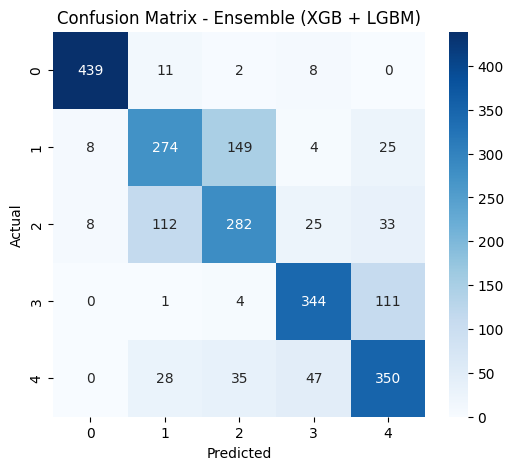

In [34]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute confusion matrix
cm_ensemble = confusion_matrix(y_test, ensemble_pred)

# Plot
plt.figure(figsize=(6,5))
sns.heatmap(cm_ensemble,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=[0,1,2,3,4],
            yticklabels=[0,1,2,3,4])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Ensemble (XGB + LGBM)")
plt.show()


In [31]:
import numpy as np

X_train_dl = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_dl = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)


In [36]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout, Flatten
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train, num_classes=5)
y_test_cat = to_categorical(y_test, num_classes=5)

model = Sequential([
    Conv1D(filters=64, kernel_size=3, activation="relu", input_shape=(X_train_dl.shape[1], 1)),
    MaxPooling1D(pool_size=2),

    Conv1D(filters=128, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),

    LSTM(64, return_sequences=False),
    Dropout(0.4),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(5, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

history = model.fit(
    X_train_dl, y_train_cat,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    verbose=2
)

score = model.evaluate(X_test_dl, y_test_cat, verbose=2)
print("\nTest Accuracy:", score[1])


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 176, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 88, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 86, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 43, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,333 (325.52 KB)

 Trainable params: 83,333 (325.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
130/130 - 6s - 43ms/step - accuracy: 0.4452 - loss: 1.1663 - val_accuracy: 0.6076 - val_loss: 0.8357
Epoch 2/100
130/130 - 1s - 8ms/step - accuracy: 0.6232 - loss: 0.8307 - val_accuracy: 0.6609 - val_loss: 0.7247
Epoch 3/100
130/130 - 1s - 8ms/step - accuracy: 0.6435 - loss: 0.7774 - val_accuracy: 0.6913 - val_loss: 0.6632
Epoch 4/100
130/130 - 1s - 8ms/step - accuracy: 0.6727 - loss: 0.6934 - val_accuracy: 0.6957 - val_loss: 0.6425
Epoch 5/100
130/130 - 1s - 8ms/step - accuracy: 0.6784 - loss: 0.6762 - val_accuracy: 0.6891 - val_loss: 0.6581
Epoch 6/100
130/130 - 1s - 8ms/step - accuracy: 0.6948 - loss: 0.6431 - val_accuracy: 0.7011 - val_loss: 0.6302
Epoch 7/100
130/130 - 1s - 8ms/step - accuracy: 0.6994 - loss: 0.6283 - val_accuracy: 0.6837 - val_loss: 0.6330
Epoch 8/100
130/130 - 1s - 8ms/step - accuracy: 0.7035 - loss: 0.6223 - val_accuracy: 0.7076 - val_loss: 0.5940
Epoch 9/100
130/130 - 1s - 11ms/step - accuracy: 0.7051 - loss: 0.6077 - val_accuracy: 0.7359 - val_los

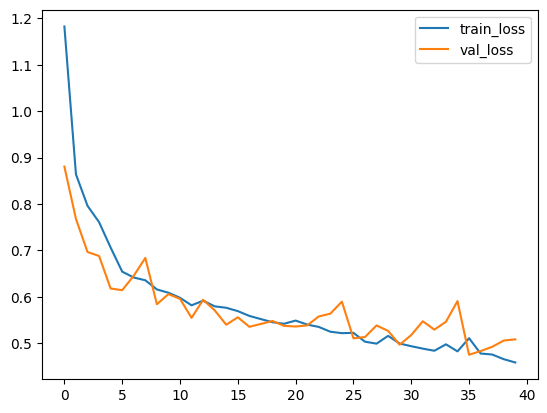

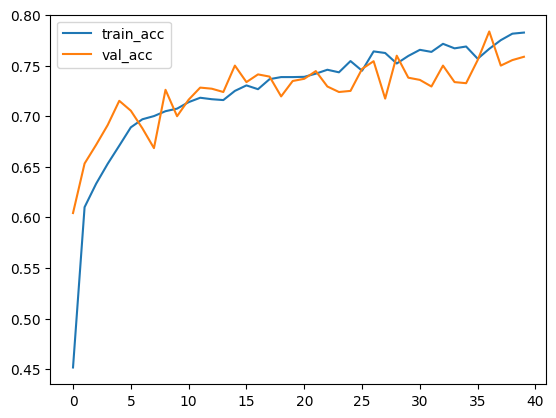

In [33]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.legend()
plt.show()

plt.plot(history.history["accuracy"], label="train_acc")
plt.plot(history.history["val_accuracy"], label="val_acc")
plt.legend()
plt.show()


72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


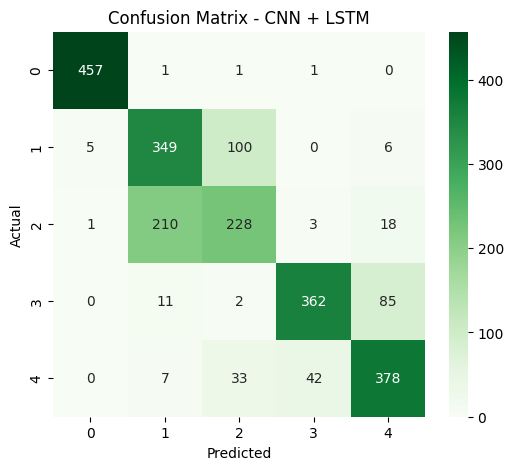

In [35]:
# Predict probabilities
y_pred_prob = model.predict(X_test_dl)

# Convert to class labels
y_pred_cnn = y_pred_prob.argmax(axis=1)

# Confusion matrix
cm_cnn = confusion_matrix(y_test, y_pred_cnn)

plt.figure(figsize=(6,5))
sns.heatmap(cm_cnn,
            annot=True,
            fmt="d",
            cmap="Greens",
            xticklabels=[0,1,2,3,4],
            yticklabels=[0,1,2,3,4])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - CNN + LSTM")
plt.show()


In [39]:
import joblib

# Save models
joblib.dump(xgb, "/content/drive/MyDrive/miniprojects/ecommerce_classification/xgb_model.pkl")
joblib.dump(lgbm, "/content/drive/MyDrive/miniprojects/ecommerce_classification/lgbm_model.pkl")


print("Ensemble models saved successfully!")


Ensemble models saved successfully!


In [37]:
model.save("/content/drive/MyDrive/miniprojects/ecommerce_classification/cnn_lstm_model.h5")

print("CNN+LSTM model saved successfully!")


CNN+LSTM model saved successfully!


In [38]:
from tensorflow.keras.models import load_model

cnn_lstm_loaded = load_model("/content/drive/MyDrive/miniprojects/ecommerce_classification/cnn_lstm_model.h5")

print("CNN+LSTM model loaded!")


CNN+LSTM model loaded!


In [41]:
import joblib
import numpy as np

# Load
xgb_loaded = joblib.load("/content/drive/MyDrive/miniprojects/ecommerce_classification/xgb_model.pkl")
lgbm_loaded = joblib.load("/content/drive/MyDrive/miniprojects/ecommerce_classification/lgbm_model.pkl")
scaler_loaded = joblib.load("/content/drive/MyDrive/miniprojects/ecommerce_classification/scaler.pkl")

print("Ensemble models loaded!")


Ensemble models loaded!


In [43]:
# ==============================
# LOAD MODELS + PREDICT (ONE CELL)
# ==============================

import numpy as np
import joblib
from tensorflow.keras.models import load_model

# -------- LOAD MODELS --------
xgb_loaded = joblib.load("/content/drive/MyDrive/miniprojects/ecommerce_classification/xgb_model.pkl")
lgbm_loaded = joblib.load("/content/drive/MyDrive/miniprojects/ecommerce_classification/lgbm_model.pkl")
scaler_loaded = joblib.load("/content/drive/MyDrive/miniprojects/ecommerce_classification/scaler.pkl")
cnn_lstm_loaded = load_model("/content/drive/MyDrive/miniprojects/ecommerce_classification/cnn_lstm_model.h5")

print("Models Loaded Successfully!")

# ======================================
# ENTER ALL 178 FEATURE VALUES MANUALLY
# ======================================

# ⚠️ Replace these dummy numbers with your real EEG values
input_values = [
    135,190,229,223,192,125,55,-9,-33,-38,-10,35,64,113,152,164,127,50,-47,-121,-138,-125,-101,-50,11,39,24,48,64,46,13,-19,-61,-96,-130,-132,-116,-115,-71,-14,25,19,6,9,21,13,-37,-58,-33,5,47,80,101,88,73,69,41,-13,-31,-61,-80,-77,-66,-43,5,87,129,121,88,12,-76,-150,-207,-186,-165,-148,-103,-33,40,94,75,8,-81,-155,-227,-262,-233,-218,-187,-126,-65,-12,27,61,49,9,-46,-124,-210,-281,-265,-181,-89,-4,53,53,38,43,31,34,9,-7,-34,-70,-84,-101,-70,-11,42,62,66,74,64,59,56,36,-11,-30,-43,-23,8,42,77,103,135,121,79,59,43,54,90,111,107,64,32,18,-25,-69,-65,-44,-33,-57,-88,-114,-130,-114,-83,-53,-79,-72,-85,-109,-98,-72,-65,-63,-11,10,8,-17,-15,-31,-77,-103,-127,-116,-83,-51
]

# Convert to numpy array
input_array = np.array(input_values).reshape(1, -1)

# Check correct feature length
if input_array.shape[1] != 178:
    raise ValueError(f"Expected 178 features, but got {input_array.shape[1]}")

# -------- SCALE INPUT --------
input_scaled = scaler_loaded.transform(input_array)

# ======================================
# 1️⃣ ENSEMBLE PREDICTION (XGB + LGBM)
# ======================================

proba_xgb = xgb_loaded.predict_proba(input_scaled)
proba_lgbm = lgbm_loaded.predict_proba(input_scaled)

avg_proba = (proba_xgb + proba_lgbm) / 2
ensemble_pred = np.argmax(avg_proba, axis=1)

# ======================================
# 2️⃣ CNN + LSTM PREDICTION
# ======================================

input_dl = input_scaled.reshape(1, input_scaled.shape[1], 1)

cnn_pred_prob = cnn_lstm_loaded.predict(input_dl)
cnn_pred = np.argmax(cnn_pred_prob, axis=1)

# ======================================
# CLASS LABEL MAPPING
# ======================================

class_names = ["Seizure", "Tumor", "Healthy", "Eyes Closed", "Eyes Open"]

print("\n===== FINAL PREDICTIONS =====")
print("Ensemble Model Prediction:", class_names[ensemble_pred[0]])
print("CNN + LSTM Prediction:", class_names[cnn_pred[0]])


Models Loaded Successfully!
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step

===== FINAL PREDICTIONS =====
Ensemble Model Prediction: Eyes Closed
CNN + LSTM Prediction: Eyes Closed


In [44]:
!python

Python 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0] on linux
Type "help", "copyright", "credits" or "license" for more information.
>>> 

KeyboardInterrupt
>>> 
KeyboardInterrupt
>>> ^C


In [45]:
!pip freeze > /content/drive/MyDrive/miniprojects/ecommerce_classification/requirements.txt